In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y operarios necesarios se adjunta. La empresa se plantea cuántos operarios contratar para el proyecto.

In [3]:
pregunta_1 = "1. ¿Es posible ejecutar el proyecto con 5 operarios? Razónelo mirando sólo el cuadro de datos.  "
pregunta_2 = "2. ¿Cuál es el número máximo de operarios que haría falta para ejecutar el proyecto en su duración mínima con las actividades en su inicio más temprano? ¿Y tras nivelar?  "
pregunta_3 = "3. Construya la tabla «operarios disponibles → duración del proyecto» aplicando el algoritmo de asignación para cada número de operarios entre el mínimo factible y el máximo necesario.  "
pregunta_4 = "4. Si cada operario cuesta 2 k€ por semana contratado durante todo el proyecto y cada semana de duración tiene un coste fijo de 5 k€, ¿cuántos operarios conviene contratar?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. ¿Es posible ejecutar el proyecto con 5 operarios? Razónelo mirando sólo el cuadro de datos.  

2. ¿Cuál es el número máximo de operarios que haría falta para ejecutar el proyecto en su duración mínima con las actividades en su inicio más temprano? ¿Y tras nivelar?  

3. Construya la tabla «operarios disponibles → duración del proyecto» aplicando el algoritmo de asignación para cada número de operarios entre el mínimo factible y el máximo necesario.  

4. Si cada operario cuesta 2 k€ por semana contratado durante todo el proyecto y cada semana de duración tiene un coste fijo de 5 k€, ¿cuántos operarios conviene contratar?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 6       , 1        ),
    ('B'     , '---'      , 5       , 5        ),
    ('C'     , 'A'        , 1       , 5        ),
    ('D'     , 'B,C'      , 4       , 2        ),
    ('E'     , 'D'        , 1       , 6        ),
    ('F'     , 'D'        , 5       , 2        ),
    ('G'     , 'E'        , 6       , 1        ),
    ('H'     , 'E,F'      , 3       , 1        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,6,1
B,---,5,5
C,A,1,5
D,"B,C",4,2
E,D,1,6
F,D,5,2
G,E,6,1
H,"E,F",3,1


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_minima = proyecto.duration(datos_proyecto['duration'])

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. ¿Es posible ejecutar el proyecto con 5 operarios? Razónelo mirando sólo el cuadro de datos.  

In [7]:
limite = 5
imposibles = datos_proyecto.index[datos_proyecto['resources'] > limite].tolist()
Markdown(f'No: {", ".join(imposibles)} necesita(n) {int(datos_proyecto["resources"].max())} operarios a la vez, más que los {limite} disponibles, '
         'y una actividad no puede ejecutarse con menos operarios de los que requiere (no se admite alargarla). El mínimo factible es el máximo requerido por una actividad.')

No: E necesita(n) 6 operarios a la vez, más que los 5 disponibles, y una actividad no puede ejecutarse con menos operarios de los que requiere (no se admite alargarla). El mínimo factible es el máximo requerido por una actividad.

## Apartado 2

In [8]:
display(Markdown(pregunta_2))

2. ¿Cuál es el número máximo de operarios que haría falta para ejecutar el proyecto en su duración mínima con las actividades en su inicio más temprano? ¿Y tras nivelar?  

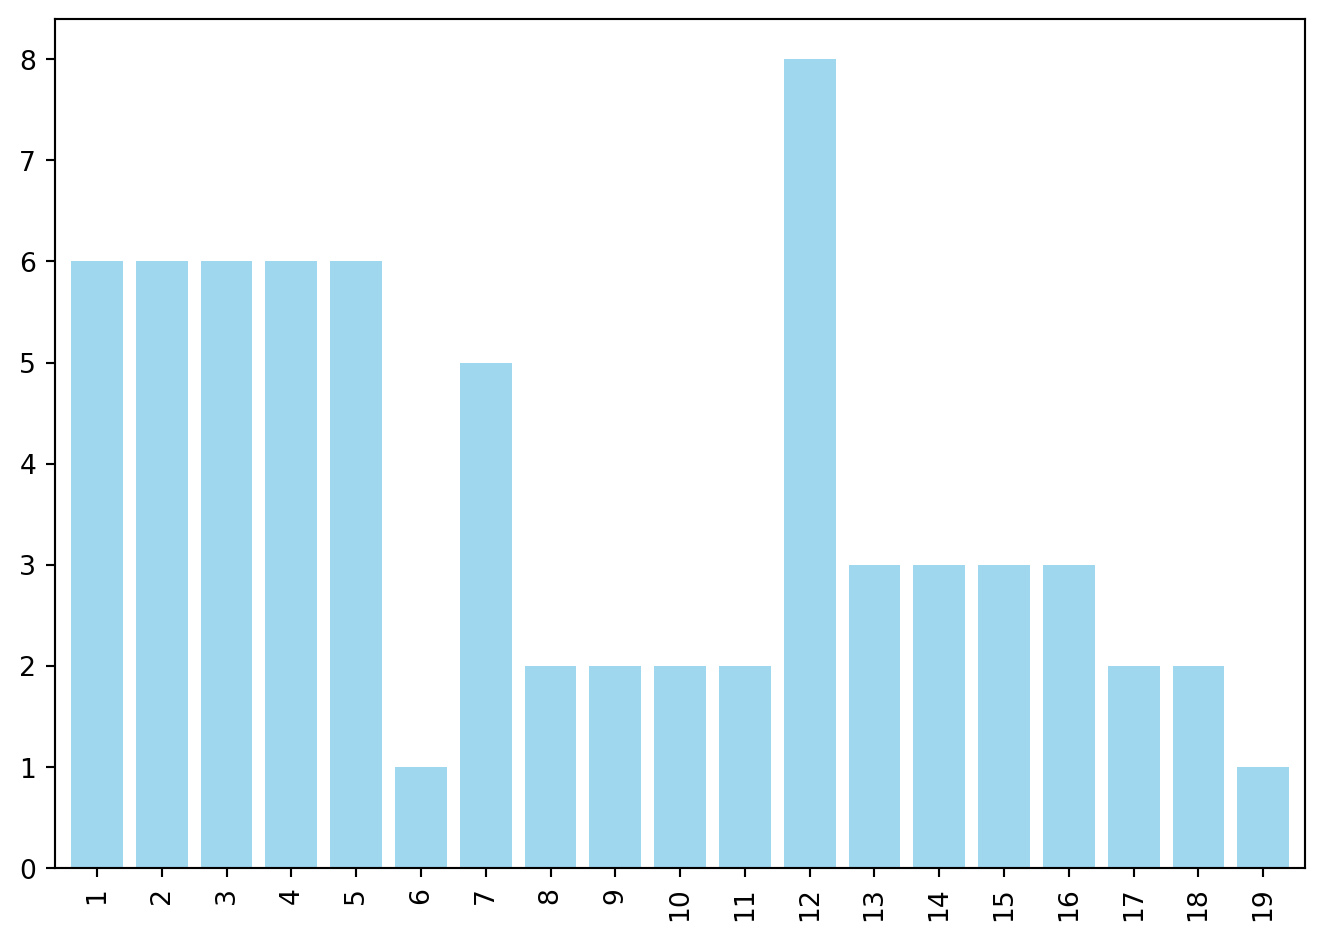

In [9]:
#| fig-cap: "Cargas con las actividades en su inicio más temprano"
#| label: fig-cargasInicial
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=None)

In [10]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
Markdown(f'Máximo de operarios: {int(cargas.max())} con inicios más tempranos y {int(cargas_niveladas.max())} tras nivelar (duración {duracion_minima} en ambos casos).')

Máximo de operarios: 8 con inicios más tempranos y 8 tras nivelar (duración 19 en ambos casos).

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Construya la tabla «operarios disponibles → duración del proyecto» aplicando el algoritmo de asignación para cada número de operarios entre el mínimo factible y el máximo necesario.  

In [12]:
minimo = int(datos_proyecto['resources'].max())
maximo = int(cargas_niveladas.max())
filas = {}
for L in range(minimo, maximo + 1):
    p = proyecto.copy()
    _, g, _ = p.asignar(data=datos_proyecto.copy(), duration_label='duration', resource_label='resources', maximo=[L], report=False)
    filas[L] = len(g.data.columns.drop('H_total'))
tabla = pd.Series(filas, name='duración (semanas)').rename_axis('operarios').to_frame()
tabla.T

operarios,6,7,8
duración (semanas),23,23,19


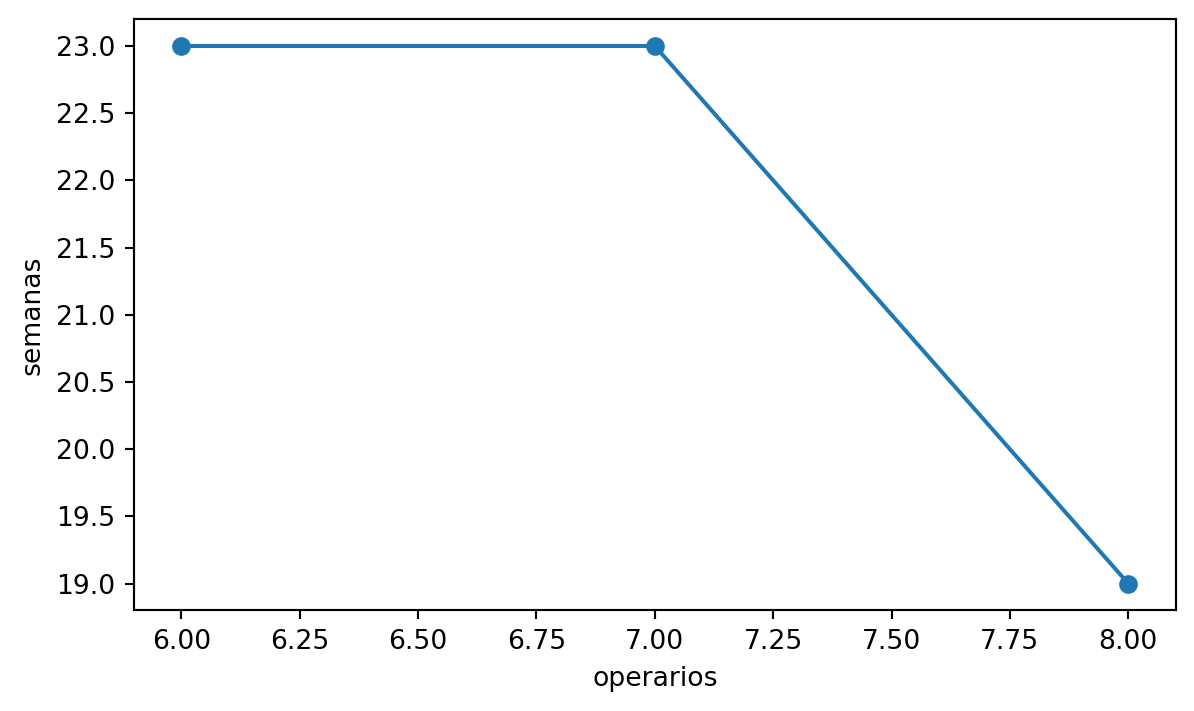

In [13]:
#| fig-cap: "Duración del proyecto según los operarios disponibles"
#| label: fig-duracionOperarios
ax = tabla.plot(marker='o', legend=False, figsize=(7, 4)); ax.set_ylabel('semanas');

## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Si cada operario cuesta 2 k€ por semana contratado durante todo el proyecto y cada semana de duración tiene un coste fijo de 5 k€, ¿cuántos operarios conviene contratar?  

In [15]:
tabla['coste operarios'] = 2 * tabla.index * tabla['duración (semanas)']
tabla['coste fijo'] = 5 * tabla['duración (semanas)']
tabla['coste total'] = tabla['coste operarios'] + tabla['coste fijo']
display(tabla)
Markdown(f'El coste total es mínimo con {tabla["coste total"].idxmin()} operarios ({tabla["coste total"].min():.0f} k€). '
         'Más operarios acortan el proyecto pero cuestan cada semana; la tabla duración-operarios tiene escalones porque la asignación es heurística y el plazo sólo baja cuando el límite libera un cuello de botella.')

,duración (semanas),coste operarios,coste fijo,coste total
operarios,,,,
6,23,276,115,391
7,23,322,115,437
8,19,304,95,399


El coste total es mínimo con 6 operarios (391 k€). Más operarios acortan el proyecto pero cuestan cada semana; la tabla duración-operarios tiene escalones porque la asignación es heurística y el plazo sólo baja cuando el límite libera un cuello de botella.